# Prompt engineering against training

Compares asking for a library in the prompt with training for it, on Qwen3-8B. Each model (the base model, or one of experiment 01's GRPO runs, named by its reward) is evaluated with each prompt style:

- **no suffix**: the task as it is (the `base` prompt style);
- **"appropriate"**: the task plus *"Use an external library when appropriate."* (see `TASK_SUFFIXES` in `src/prompts.py`).

The "always" prompt (*"Always use an external library in your solution."*) has results too, but is left out of these figures, to keep for an appendix ablation. A prompt style is only shown once every model has results for it. Each trained run is shown at one epoch, named under its bars: of the epochs evaluated with every prompt style shown, the one where the run used a library most often on LibReuseBench test with no suffix. That choice looks at test results, so it is a best case for training.

Two figures are saved: the key results (library use, pass@1 and the lines of code reuse saves, on LibReuseBench test), and the details (also LibReuseBench control, the general coding benchmarks HumanEval+ and LiveCodeBench, and the lines of code per answer).

Lines saved are measured as in `01_grpo_training_summary.ipynb`: an answer that uses a library saves however many lines of code shorter it is than the base model's average hand-written answer (no suffix) to the same task, and an answer without a library saves 0. Tasks the base model never answered by hand have nothing to compare against, so they are left out.

Each value is computed from the saved generations: the average within each task's samples, then over tasks (for pass@1, the same unbiased estimate the evaluators report). Error bars are ±1 standard error over tasks.

In [1]:
"""Compare prompt engineering with GRPO training on library use and pass@1."""

import json
import os
from functools import cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from llm_cgr import load_jsonl
from matplotlib.axes import Axes
from matplotlib.ticker import PercentFormatter

from src.utils.config import load_model_settings
from src.utils.paths import baseline_dir, model_output_dir

# run from the repo root (the folder holding .git), so the relative paths src uses
# (config/, output/) resolve - this notebook lives beside its results, in output/
REPO_ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / ".git").exists()
)
os.chdir(REPO_ROOT)

BASE_MODEL = "qwen3-8b"
# experiment 01's training runs, by the reward each was trained with, in the order the
# figures show them (after the base model)
RUNS = {
    "import": "qwen3-8b-4474",
    "usage": "qwen3-8b-cc26",
    "target": "qwen3-8b-1f71",
}
EPOCHS = range(1, 9)
DECODING_PROFILE = "default_16k"

# the prompt styles, as their result files name them, and as the legend does. "always" has
# results too, kept for an appendix ablation rather than these figures
PROMPT_STYLES = {
    "base": "no suffix",
    "appropriate": '+ "Use an external library when appropriate."',
}

# the key results figure: (dataset, metric, title) per panel
MAIN_PANELS = [
    ("libreusebench_test", "uses a library", "(a) responses using a library"),
    ("libreusebench_test", "pass@1", "(b) pass@1 (responses passing every test)"),
    (
        "libreusebench_test",
        "lines saved",
        "(c) lines of code saved by library reuse, per answer",
    ),
]
# the details figure, in reading order: library use, pass@1, then the general coding
# benchmarks, for libreusebench's test split on the top row and its control split below,
# then the size of the answers on the bottom row
DETAIL_PANELS = [
    ("libreusebench_test", "uses a library", "(a) LibReuseBench test: using a library"),
    ("libreusebench_test", "pass@1", "(b) LibReuseBench test: pass@1"),
    ("humaneval_plus", "pass@1", "(c) HumanEval+: pass@1"),
    (
        "libreusebench_control",
        "uses a library",
        "(d) LibReuseBench control: using a library",
    ),
    ("libreusebench_control", "pass@1", "(e) LibReuseBench control: pass@1"),
    ("livecodebench", "pass@1", "(f) LiveCodeBench: pass@1"),
    (
        "libreusebench_test",
        "lines of code",
        "(g) LibReuseBench test: lines of code per answer",
    ),
    (
        "libreusebench_test",
        "lines saved",
        "(h) LibReuseBench test: lines saved by reuse, per answer",
    ),
    (
        "libreusebench_control",
        "lines of code",
        "(i) LibReuseBench control: lines of code per answer",
    ),
]

# the metrics that are rates (shown as percentages); the others are lines of code
RATE_METRICS = {"uses a library", "pass@1"}

# the results each trained run's epoch is chosen on (with no suffix)
CHOICE_DATASET, CHOICE_METRIC = "libreusebench_test", "uses a library"

MAIN_FILE = (
    Path("output") / "03_epoch_ablation" / "figures" / "prompt_engineering_summary.png"
)
DETAILS_FILE = (
    Path("output") / "03_epoch_ablation" / "figures" / "prompt_engineering_details.png"
)

In [2]:
# chart colours and style, as in 01_grpo_training_summary.ipynb so the figures match
INK = "#52514e"  # text
SURFACE = "#fcfcfb"  # chart background
RULE = "#c3c2b7"  # axes

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": RULE,
        "axes.labelcolor": INK,
        "axes.titlesize": 10,
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "xtick.color": RULE,
        "ytick.color": RULE,
        "xtick.labelcolor": INK,
        "ytick.labelcolor": INK,
        "font.size": 9,
        "legend.frameon": False,
        "legend.fontsize": 8.5,
    }
)

# one colour per prompt style, two slots of a categorical palette (checked for
# colour-blindness against the chart background with a palette validator)
STYLE_COLOURS = {
    "base": "#2a78d6",  # blue
    "appropriate": "#1baf7a",  # aqua
}

In [3]:
@cache
def hand_written_lines(
    dataset: str,
) -> pd.Series:
    """
    The base model's average hand-written answer (no library, no suffix) to each of a
    dataset's tasks, in lines of code - what an answer that reuses a library is compared with.

    Returns the lines of code per task, for the tasks the base model answered by hand.
    """
    generations_file = (
        baseline_dir(BASE_MODEL)
        / f"{dataset}-{DECODING_PROFILE}-base.generations.jsonl"
    )
    records = pd.DataFrame(load_jsonl(file_path=str(generations_file)))
    by_hand = records[records["lloc"].notna() & ~records["external_lib_used"]]
    return by_hand.groupby("task_id")["lloc"].mean()


def response_values(
    records: pd.DataFrame,
    dataset: str,
    metric: str,
) -> pd.Series:
    """
    Each response's value for a metric: 1 or 0 for using a library and for passing, its
    lines of code, or the lines of code it saved by reuse (see the notes at the top). A
    response without a value - no code, or a task the base model never answered by hand -
    gets NaN.

    Returns one value per response.
    """
    if metric == "uses a library":
        return records["external_lib_used"].astype(float)
    if metric == "pass@1":
        return records["passed"].astype(float)
    if metric == "lines of code":
        return records["lloc"]
    # lines saved: shorter than the hand-written reference if it uses a library, else 0
    reference = records["task_id"].map(hand_written_lines(dataset))
    saved = (reference - records["lloc"]).where(records["external_lib_used"], 0.0)
    return saved.where(records["lloc"].notna() & reference.notna())


def task_values(
    results_file: Path,
    dataset: str,
    metric: str,
) -> pd.Series | None:
    """
    A metric's average within each task's samples (see response_values), read from the
    generations saved beside a results file. Tasks with no value at all are left out.

    Returns one value per task, or None if there are no results yet.
    """
    generations_file = results_file.with_suffix(".generations.jsonl")
    if not generations_file.exists():
        return None
    records = pd.DataFrame(load_jsonl(file_path=str(generations_file)))
    values = response_values(records=records, dataset=dataset, metric=metric)
    return values.groupby(records["task_id"]).mean().dropna()


# each model's results folder: the base model's, then each run's epoch checkpoints'
MODELS = ["base model", *(f"{reward} reward" for reward in RUNS)]
model_dirs: dict[tuple[str, int], Path] = {("base model", 0): baseline_dir(BASE_MODEL)}
for reward, run_id in RUNS.items():
    for epoch in EPOCHS:
        model_key = f"{run_id}-epoch{epoch}"
        model_dirs[f"{reward} reward", epoch] = model_output_dir(
            model_key=model_key,
            model_settings=load_model_settings(model_key=model_key),
        )

# every (dataset, metric) the figures need, once
measures = list(
    dict.fromkeys((dataset, metric) for dataset, metric, _ in DETAIL_PANELS)
)

rows = []
for (model, epoch), model_dir in model_dirs.items():
    for style in PROMPT_STYLES:
        for dataset, metric in measures:
            results_file = model_dir / f"{dataset}-{DECODING_PROFILE}-{style}.json"
            rates = task_values(
                results_file=results_file, dataset=dataset, metric=metric
            )
            if rates is None:
                continue
            rows.append(
                {
                    "model": model,
                    "style": style,
                    "epoch": epoch,
                    "dataset": dataset,
                    "metric": metric,
                    "value": rates.mean(),
                    "standard_error": rates.std(ddof=1) / np.sqrt(len(rates)),
                    "n_tasks": len(rates),
                }
            )
results = pd.DataFrame(rows)
choice = results[
    (results["dataset"] == CHOICE_DATASET) & (results["metric"] == CHOICE_METRIC)
]

# the prompt styles every model has results for
STYLES_SHOWN = [
    style
    for style in PROMPT_STYLES
    if choice[choice["style"] == style]["model"].nunique() == len(MODELS)
]

# each model's epoch: of the epochs with results for every style shown, the one with the
# most library use with no suffix (the base model has only its own "epoch 0")
styles_per_epoch = (
    choice[choice["style"].isin(STYLES_SHOWN)]
    .groupby(["model", "epoch"])["style"]
    .nunique()
)
complete_epochs = styles_per_epoch[styles_per_epoch == len(STYLES_SHOWN)].index
no_suffix = choice[choice["style"] == "base"].set_index(["model", "epoch"])
no_suffix = no_suffix[no_suffix.index.isin(complete_epochs)].reset_index()
CHOSEN_EPOCHS = no_suffix.loc[no_suffix.groupby("model")["value"].idxmax()].set_index(
    "model"
)["epoch"]

shown = results[
    results["style"].isin(STYLES_SHOWN)
    & (results["epoch"] == results["model"].map(CHOSEN_EPOCHS))
]
print("prompt styles shown:", STYLES_SHOWN)
print("epochs shown:", CHOSEN_EPOCHS.to_dict())

# the table view of the figures: every bar's value, rates as percentages
table = shown.pivot_table(
    index=["model", "epoch", "style"],
    columns=["dataset", "metric"],
    values="value",
    sort=False,
)
display(
    table.style.format(
        {
            column: "{:.1%}" if column[1] in RATE_METRICS else "{:.1f}"
            for column in table.columns
        },
        na_rep="–",
    )
)

prompt styles shown: ['base', 'appropriate']
epochs shown: {'base model': 0, 'import reward': 2, 'target reward': 3, 'usage reward': 3}


In [4]:
# the group of bars for each model, and its label (trained runs say which epoch they show)
GROUP_POSITIONS = np.arange(len(MODELS))
GROUP_LABELS = [
    model if model == "base model" else f"{model}\n(epoch {CHOSEN_EPOCHS[model]})"
    for model in MODELS
]
BAR_WIDTH = 0.8 / len(STYLES_SHOWN)

# how the evals sampled, for the notes (every model and prompt is sampled alike)
decoding = json.loads(
    (
        baseline_dir(BASE_MODEL) / f"libreusebench_test-{DECODING_PROFILE}-base.json"
    ).read_text()
)["metadata"]["decoding_settings"]
NOTES = (
    "each trained run is shown at one epoch: of the epochs evaluated with every prompt "
    "shown, the one where it used a library most often on LibReuseBench test with no "
    "suffix - a best case for training, as it is chosen on test results. "
    "lines saved: how many lines of code shorter an answer using a library is than the base "
    "model's average hand-written answer (no suffix) to the same task, and 0 for an answer "
    f"without one. error bars: ±1 standard error over tasks. {decoding['n_samples']} "
    f"samples per task at temperature {decoding['temperature']:g}, up to "
    f"{decoding['max_new_tokens']:,} tokens."
)


def plot_bars(
    ax: Axes,
    dataset: str,
    metric: str,
    title: str,
    value_labels: bool = False,
) -> None:
    """
    Draw one panel: a group of bars per model, one bar per prompt style shown, each with
    its standard error. `value_labels` writes each bar's value above it. A rate is shown as
    a percentage from 0 to 100%, lines of code from 0.
    """
    is_rate = metric in RATE_METRICS
    panel = shown[(shown["dataset"] == dataset) & (shown["metric"] == metric)]
    for offset, style in enumerate(STYLES_SHOWN):
        bars = panel[panel["style"] == style].set_index("model").reindex(MODELS)
        # the style's bar in each model's group, the group's bars centred on its label
        positions = GROUP_POSITIONS + (offset - (len(STYLES_SHOWN) - 1) / 2) * BAR_WIDTH
        ax.bar(
            positions,
            bars["value"],
            width=BAR_WIDTH,
            color=STYLE_COLOURS[style],
            # a thin gap of background between neighbouring bars
            edgecolor=SURFACE,
            linewidth=1.5,
            label=PROMPT_STYLES[style],
        )
        ax.errorbar(
            positions,
            bars["value"],
            yerr=bars["standard_error"],
            fmt="none",
            ecolor=INK,
            elinewidth=1,
        )
        if value_labels:
            for x, value, error in zip(
                positions, bars["value"], bars["standard_error"]
            ):
                if pd.notna(value):
                    ax.annotate(
                        f"{value:.0%}" if is_rate else f"{value:.1f}",
                        xy=(x, value + error),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha="center",
                        va="bottom",
                        color=INK,
                        fontsize=8,
                    )
    if panel.empty:
        ax.text(
            0.5, 0.5, "no results yet", transform=ax.transAxes, ha="center", color=INK
        )
    ax.set_title(title)
    if is_rate:
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    else:
        # from 0, with room above the tallest bar for its label
        ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
    ax.set_xticks(GROUP_POSITIONS, labels=GROUP_LABELS)
    # fixed, so a panel still waiting for results lines up with the others
    ax.set_xlim(-0.6, len(MODELS) - 0.4)
    ax.tick_params(axis="x", length=0)

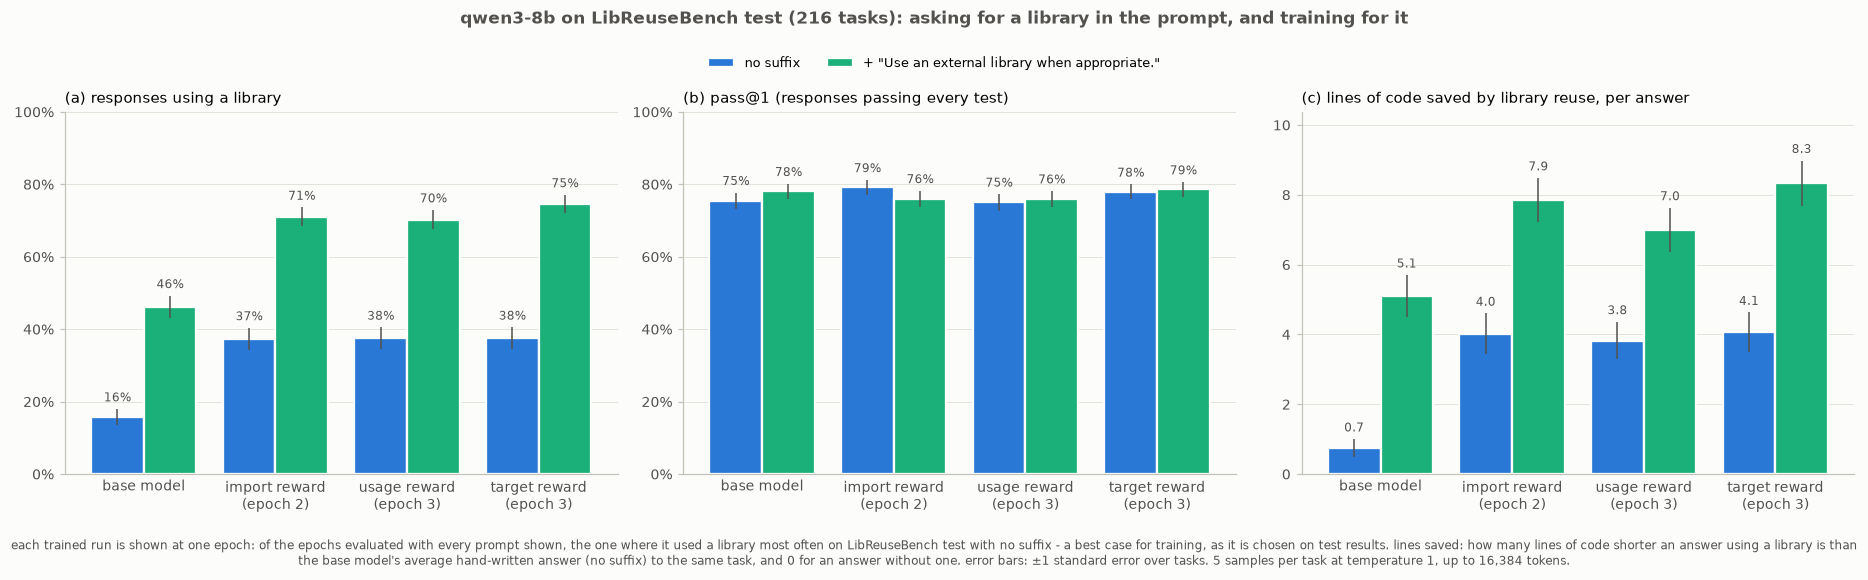

In [5]:
# the key results: library use, pass@1 and lines saved on libreusebench test, side by side
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (dataset, metric, title) in zip(axes, MAIN_PANELS):
    plot_bars(
        ax=ax,
        dataset=dataset,
        metric=metric,
        title=title,
        value_labels=True,
    )

n_tasks = shown[shown["dataset"] == CHOICE_DATASET]["n_tasks"].max()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncols=len(STYLES_SHOWN),
    bbox_to_anchor=(0.5, 1.0),
)
fig.suptitle(
    f"{BASE_MODEL} on LibReuseBench test ({n_tasks} tasks): asking for a library in the "
    "prompt, and training for it",
    color=INK,
    fontsize=11,
    fontweight="bold",
    y=1.07,
)
fig.text(0.5, -0.02, NOTES, ha="center", va="top", color=INK, fontsize=8, wrap=True)
fig.tight_layout()
MAIN_FILE.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(MAIN_FILE, dpi=200, bbox_inches="tight")
plt.show()

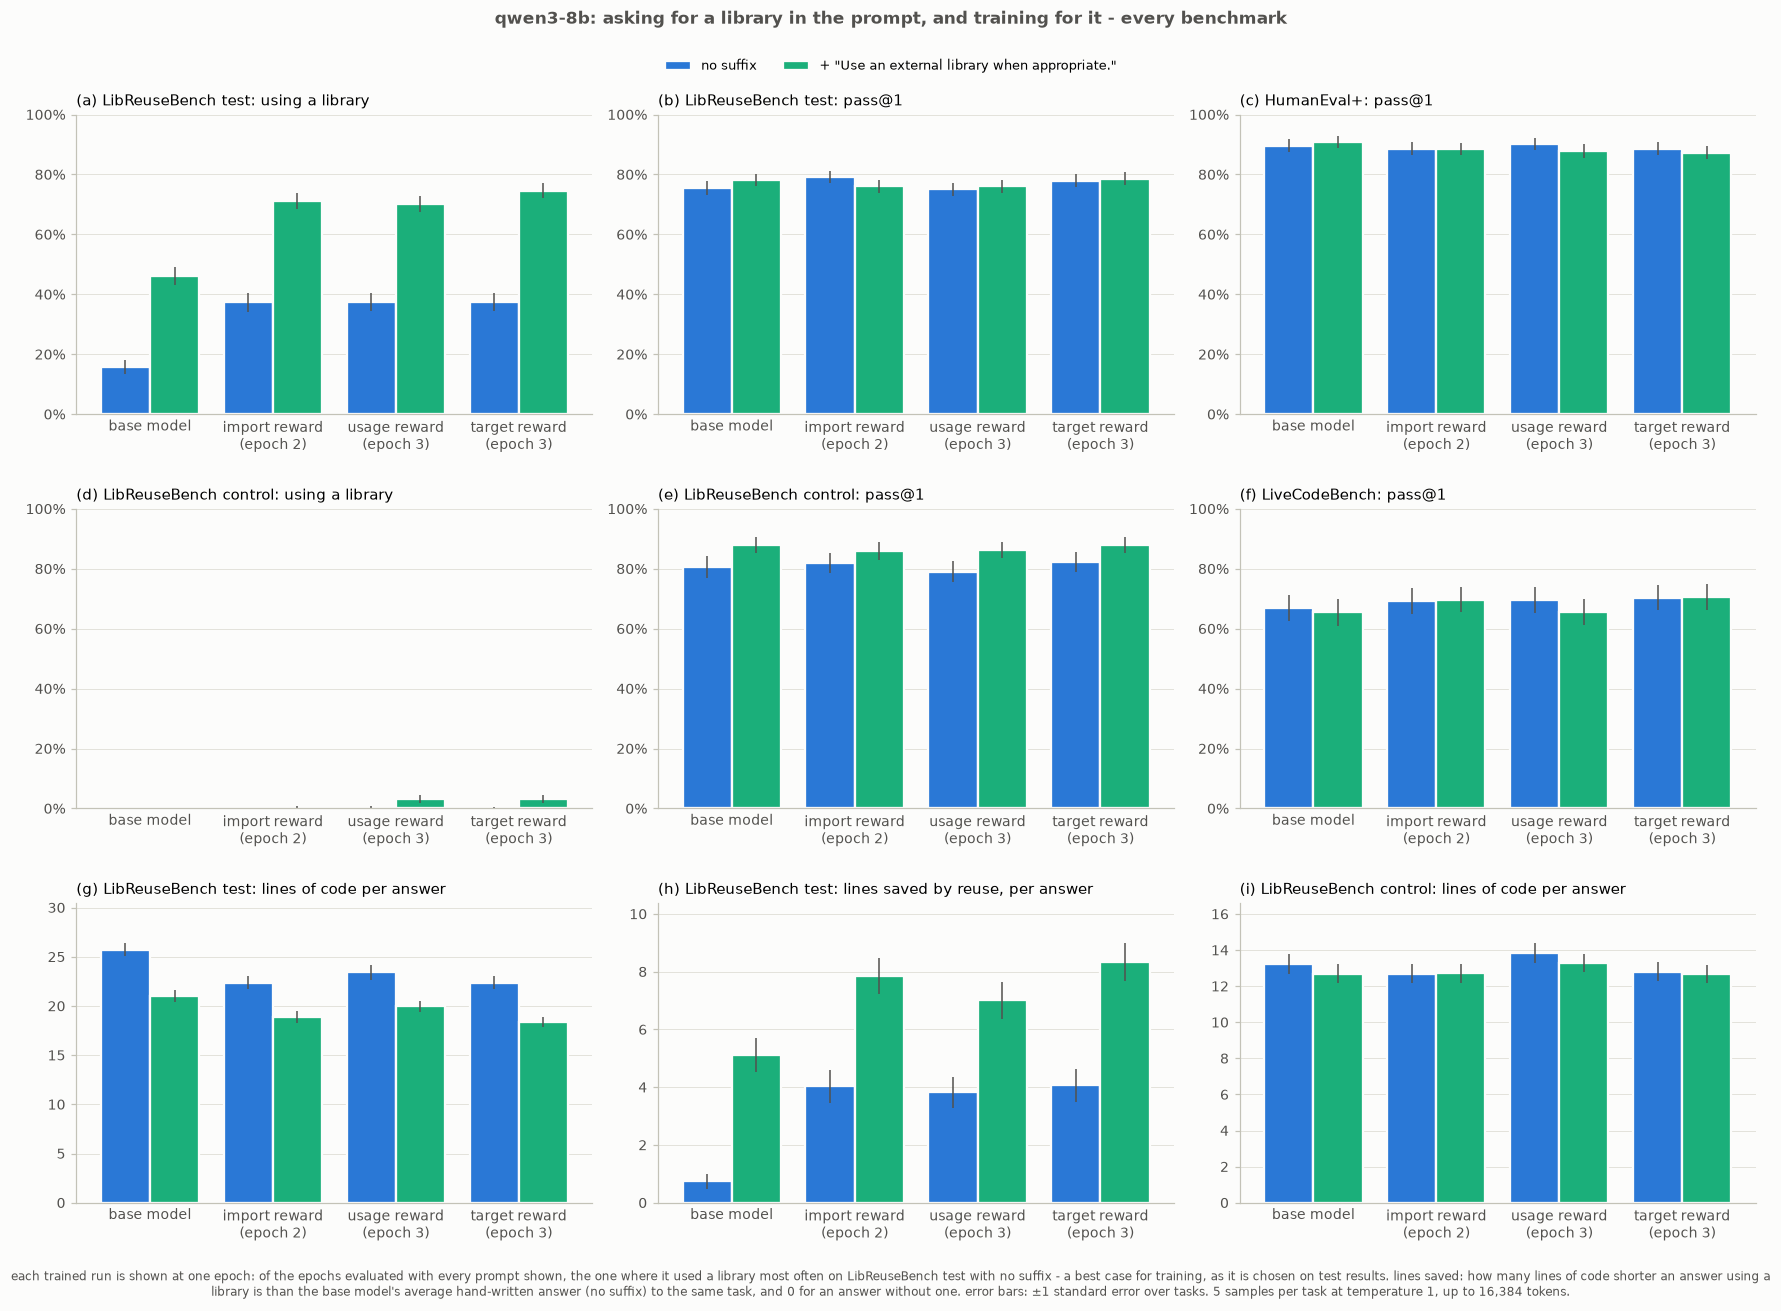

In [6]:
# the details: libreusebench's test and control splits, the general coding benchmarks, and
# the size of the answers
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, (dataset, metric, title) in zip(axes.flat, DETAIL_PANELS):
    plot_bars(ax=ax, dataset=dataset, metric=metric, title=title)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncols=len(STYLES_SHOWN),
    bbox_to_anchor=(0.5, 1.0),
)
fig.suptitle(
    f"{BASE_MODEL}: asking for a library in the prompt, and training for it - every benchmark",
    color=INK,
    fontsize=11,
    fontweight="bold",
    y=1.03,
)
fig.text(0.5, -0.01, NOTES, ha="center", va="top", color=INK, fontsize=8, wrap=True)
fig.tight_layout(h_pad=2.5)
fig.savefig(DETAILS_FILE, dpi=200, bbox_inches="tight")
plt.show()